# OLS：Stata 实验 {#sec-ols-lab}

[返回理论篇](../../lectures/ols.qmd) · [数据说明](../../data/ols/README.md) · [完整 do-file](../../tools/ols/ols_ch1_run.do)

本实验使用冻结的 Mroz 数据，研究就业女性的小时工资与教育年限。先检查样本，再比较组均值与回归直线，最后核对三条 OLS 代数性质。

从仓库根目录执行 `python tools/ols/run_notebook.py` 可重新运行。下方输出由 Stata 实际产生；网页只展示已保存结果。


In [1]:
%%quietly
local project_root : environment FINECO_ROOT
if "`project_root'" != "" {
    cd "`project_root'"
}
confirm file "data/ols/mroz.dta"



Running D:\stata19/profile.do ...



## 样本、估计与代数检查

官方文件把 325 名未就业女性的工资编码为 0；本实验明确筛选 `inlf == 1`。回归输出中应看到 `Number of obs = 428`、教育系数约 0.4953、常规标准误约 0.06595。分组图使用同一批个体，标签为各组样本量。

残差矩接近零只说明 OLS 拟合代数成立，不能据此判断教育是外生变量。


(Note: Below code run with echo to enable preserve/restore functionality.)













Stata version: 19.5


not available in non-GUI version

  753

  753




(325 observations deleted)











      Source |       SS           df       MS      Number of obs   =       428
-------------+----------------------------------   F(1, 426)       =     56.41
       Model |   547.13493         1   547.13493   Prob > F        =    0.0000
    Residual |    4131.918       426  9.69933804   R-squared       =    0.1169
-------------+----------------------------------   Adj R-squared   =    0.1149
       Total |  4679.05293       427  10.9579694   Root MSE        =    3.1144



------------------------------------------------------------------------------


        wage | Coefficient  Std. err.      t    P>|t|     [95% conf. interval]


...

------------------------------------------------------------------------------













































(0 observations deleted)





(1 missing value generated)

(1 missing value generated)

(1 missing value generated)

(1 missing value generated)




file output/ols/tables/ols_cef_group_means.csv saved



file figs/raw/ols-fig03-cef-groupmeans-20260930-152321.png written in PNG forma
> t


===== FinEco OLS Chapter 1 verification =====

educ=12: mean wage=   3.8001 N=   212

educ=16: mean wage=   5.1541 N=    39

OLS: wage =   -2.0924 +    0.4953 educ

SE: cons=   0.8483 educ=   0.0659

N=   428 R2= 0.116933

mean residual=-8.39411613946e-16

sum(residual*educ)=-5.38857847232e-12

ybar - fitted(xbar)=                 0




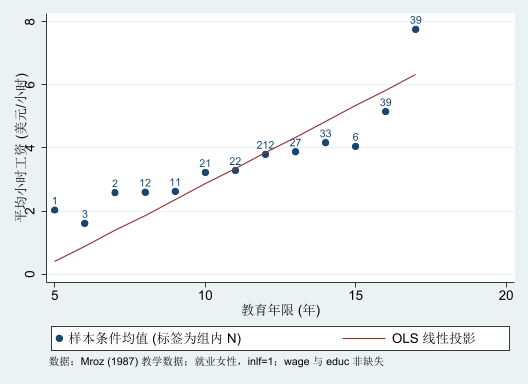

In [2]:
*******************************************************
* FinEco - Chapter OLS / Conditional Expectation
* Purpose: local Stata verification + figure generation
* 已执行核验；本脚本使用冻结的 Mroz 教学数据。
*******************************************************

version 16.0
clear all
set more off

* -----------------------------------------------------
* 0. Output folders
* Run from a writable working directory. The script writes
* to ./output/ols; full logs are local and not published.
* -----------------------------------------------------
capture mkdir "output"
capture mkdir "figs"
capture mkdir "figs/raw"
local outdir "output/ols"
capture mkdir "`outdir'"
capture mkdir "`outdir'/figures"
capture mkdir "`outdir'/tables"
capture mkdir "`outdir'/logs"


* -----------------------------------------------------
* 1. Load the public Wooldridge/Mroz teaching dataset
* -----------------------------------------------------
use "data/ols/mroz.dta", clear
display "Stata version: " c(stata_version)
set scheme s2color
graph set window fontface "Microsoft YaHei"

* Keep source variables unchanged. The wage regression uses
* only observations for which both wage and educ are observed.
count
count if !missing(wage, educ)
* 官方数据将未就业者工资编码为 0；本章研究就业女性工资。
assert wage == 0 if inlf == 0
keep if inlf == 1 & !missing(wage, educ)
assert _N == 428

* -----------------------------------------------------
* 2. Sample conditional means used in the manuscript
* -----------------------------------------------------
quietly summarize wage if educ == 12
scalar mean_wage_12 = r(mean)
scalar n_wage_12    = r(N)

quietly summarize wage if educ == 16
scalar mean_wage_16 = r(mean)
scalar n_wage_16    = r(N)

* -----------------------------------------------------
* 3. Main OLS regression and exact quantities for insertion
* -----------------------------------------------------
regress wage educ

scalar N_ols     = e(N)
scalar R2_ols    = e(r2)
scalar b_cons    = _b[_cons]
scalar b_educ    = _b[educ]
scalar se_cons   = _se[_cons]
scalar se_educ   = _se[educ]

predict double wage_hat if e(sample), xb
predict double e_hat    if e(sample), residuals

* -----------------------------------------------------
* 4. Reproducibility checks for OLS algebra
*    (a) mean residual = 0 with a constant
*    (b) sum(e_i * educ_i) = 0
*    (c) regression line passes through (xbar, ybar)
* -----------------------------------------------------
quietly summarize e_hat if e(sample), meanonly
scalar mean_resid = r(mean)

capture drop e_educ
generate double e_educ = e_hat * educ if e(sample)
quietly summarize e_educ if e(sample), meanonly
scalar sum_resid_educ = r(mean) * r(N)

quietly summarize educ if e(sample), meanonly
scalar xbar_educ = r(mean)
quietly summarize wage if e(sample), meanonly
scalar ybar_wage = r(mean)
scalar fit_at_xbar = b_cons + b_educ * xbar_educ
scalar meanpoint_gap = ybar_wage - fit_at_xbar

* -----------------------------------------------------
* 5. Export a machine-readable result file for Codex
* -----------------------------------------------------
tempname fh
file open `fh' using "`outdir'/tables/ols_ch1_results.txt", ///
    write text replace
file write `fh' "dataset=mroz" _n
file write `fh' ///
    "source=https://www.stata.com/data/jwooldridge/eacsap/mroz" _n
file write `fh' "mean_wage_educ12=" %12.8f (mean_wage_12) _n
file write `fh' "n_educ12=" %12.0f (n_wage_12) _n
file write `fh' "mean_wage_educ16=" %12.8f (mean_wage_16) _n
file write `fh' "n_educ16=" %12.0f (n_wage_16) _n
file write `fh' "N_ols=" %12.0f (N_ols) _n
file write `fh' "b_cons=" %12.8f (b_cons) _n
file write `fh' "b_educ=" %12.8f (b_educ) _n
file write `fh' "se_cons=" %12.8f (se_cons) _n
file write `fh' "se_educ=" %12.8f (se_educ) _n
file write `fh' "R2_ols=" %12.8f (R2_ols) _n
file write `fh' "mean_resid=" %18.12g (mean_resid) _n
file write `fh' "sum_resid_educ=" %18.12g (sum_resid_educ) _n
file write `fh' "xbar_educ=" %12.8f (xbar_educ) _n
file write `fh' "ybar_wage=" %12.8f (ybar_wage) _n
file write `fh' "fit_at_xbar=" %12.8f (fit_at_xbar) _n
file write `fh' "meanpoint_gap=" %18.12g (meanpoint_gap) _n
file close `fh'

* -----------------------------------------------------
* 6. Figure: sample conditional means + individual-level OLS line
* -----------------------------------------------------
preserve
    keep if !missing(wage, educ)

    * Collapse to one row per education level. The OLS line below
    * uses coefficients from the individual-level regression above.
    collapse (count) n=wage ///
             (mean) mean_wage=wage ///
             (sd) sd_wage=wage, by(educ)

    generate double ols_fit = b_cons + b_educ * educ
    generate double se_mean = sd_wage / sqrt(n) if n > 1
    generate double tcrit   = invttail(n-1, 0.025) if n > 1
    generate double ci_lo   = mean_wage - tcrit * se_mean if n > 1
    generate double ci_hi   = mean_wage + tcrit * se_mean if n > 1

    sort educ

    * Export grouped means so the figure and manuscript values can
    * be audited independently of the graph image.
    export delimited educ n mean_wage sd_wage se_mean ///
        ci_lo ci_hi ols_fit ///
        using "`outdir'/tables/ols_cef_group_means.csv", replace

    * Figure requested by the instructor:
    * one point per education level + OLS linear projection.
    * Numeric labels show the number of observations in each group.
    twoway ///
        (scatter mean_wage educ, mlabel(n) mlabposition(12)) ///
        (line ols_fit educ, sort), ///
        xtitle("教育年限 (年)") ///
        ytitle("平均小时工资 (美元/小时)") ///
        legend(order(1 "样本条件均值 (标签为组内 N)" 2 "OLS 线性投影")) ///
        note("数据：Mroz (1987) 教学数据；就业女性，inlf=1；wage 与 educ 非缺失")

    local fig "figs/raw/ols-fig03-cef-groupmeans-20260930-152321.png"
    graph export "`fig'", ///
        width(2400) replace
restore

* -----------------------------------------------------
* 7. Console summary for human audit
* -----------------------------------------------------
display as text "===== FinEco OLS Chapter 1 verification ====="
display as text "educ=12: mean wage=" %9.4f mean_wage_12 ///
    "  N=" %6.0f n_wage_12
display as text "educ=16: mean wage=" %9.4f mean_wage_16 ///
    "  N=" %6.0f n_wage_16
display as text "OLS: wage = " %9.4f b_cons " + " %9.4f b_educ " educ"
display as text "SE: cons=" %9.4f se_cons "  educ=" %9.4f se_educ
display as text "N=" %6.0f N_ols "  R2=" %9.6f R2_ols
display as text "mean residual=" %18.12g mean_resid
display as text "sum(residual*educ)=" %18.12g sum_resid_educ
display as text "ybar - fitted(xbar)=" %18.12g meanpoint_gap


## 核对结果

教育 12 年组有 212 人，平均工资约 3.800147；16 年组有 39 人，平均工资约 5.154136 美元/小时。回归直线的斜率是统计关系，不是教育的因果回报。

机器结果与分组表保存到 `output/ols/tables/`。重新执行时以刚生成的表为准，执行器会核对样本量、系数和残差正交条件。

[返回理论篇](../../lectures/ols.qmd)
